# 06 — Does the brown dwarf change when the planet reaches the star?

Start the same $1.9\,M_\oplus$ planet at **1 au at stellar age zero**. In one run it orbits the $1.2\,M_\odot$ star alone. In the other, a $27\,M_{\rm J}$ brown dwarf starts at 20 au with a mutual inclination of $60^\circ$. Both use the saved SeBa mass and radius, inner relativistic precession, equilibrium tides, tidal and rotational bulges, and wind spin loss. For the isolated control we keep the same orbit records but switch off the brown dwarf’s quadrupole and octupole perturbations. Both runs use the same check for contact between the planet and the star. The initial stellar and planetary spins are $0.1n_0$ and $n_0$.

In 05 we placed the planet at 5 au **at AGB entry**. Here the orbit evolves before the star becomes a giant. Read the recorded results below, or run all the cells for a quick comparison of the saved eccentricity peaks. The extra simulations are optional.

In [ ]:
from pathlib import Path
import json

RUN_PC_BENCHMARK = False     # Fresh timed run of the full refined triple, several hours
RUN_EARLY_COMPARISON = False  # Two triple runs from age zero to about 50 Myr
RUN_FULL_TRIPLE = False       # One original full-history case, several hours


cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "notebooks" and not (cwd / "data").is_dir() else cwd
REFERENCE = ROOT / "data/full_history_runs/full_20261114T122554Z_3cdcf4"


In [ ]:
# Setup for the optional runs and saved figures. Run once per kernel.

import hashlib as _bench_hashlib
import json
import json as _bench_json
import math
import os
import os as _bench_os
import platform as _bench_platform
import re as _bench_re
import subprocess as _bench_subprocess
import tempfile
import tempfile as _bench_tempfile
import uuid
import warnings
from contextlib import contextmanager
from datetime import datetime as _bench_datetime, timezone as _bench_timezone
from importlib import metadata as _bench_metadata
from importlib.metadata import version
from importlib.util import find_spec as _bench_find_spec
from numbers import Integral as _bench_Integral
from pathlib import Path
from pathlib import Path as _bench_Path
from time import perf_counter
from time import perf_counter as _bench_perf_counter

import numpy as np


_BENCH_SCHEMA = "amuse_pc_benchmark_v1"


def _bench_read(path):
    try:
        return _bench_Path(path).read_text(errors="replace").strip()
    except OSError:
        return ""


def _bench_sysctl(key):
    try:
        return _bench_subprocess.check_output(["sysctl", "-n", key], text=True, timeout=2,
                                       stderr=_bench_subprocess.DEVNULL).strip()
    except (OSError, _bench_subprocess.SubprocessError):
        return ""


def _bench_version(*names, source_package=None):
    for name in names:
        try:
            return _bench_metadata.version(name)
        except _bench_metadata.PackageNotFoundError:
            pass
    if source_package:
        spec = _bench_find_spec(source_package)
        if spec is not None and spec.origin:
            text = _bench_read(_bench_Path(spec.origin).with_name("_version.py"))
            match = _bench_re.search(r"""^__version__\s*=\s*["']([^"']+)["']""", text, _bench_re.M)
            if match:
                return match.group(1)
    return None


def _bench_windows_ram():
    import ctypes
    class Memory(ctypes.Structure):
        _fields_ = [("length", ctypes.c_uint32), ("load", ctypes.c_uint32),
                    ("physical", ctypes.c_uint64), ("other", ctypes.c_uint64 * 6)]
    info = Memory()
    info.length = ctypes.sizeof(info)
    if ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(info)):
        return info.physical
    return None


def machine_specs():
    """Return portable hardware and software fields without user or machine identifiers."""
    system = _bench_platform.system()
    cpu = _bench_platform.processor() or _bench_platform.machine()
    cores, ram, affinity = None, None, None
    os_name = system
    if system == "Linux":
        cpuinfo = _bench_read("/proc/cpuinfo")
        for key in ("model name", "Hardware", "Processor"):
            model = _bench_re.search(rf"^{key}\s*:\s*(\S[^\n]*)", cpuinfo, _bench_re.M)
            if model:
                cpu = model.group(1).strip()
                break
        core_pairs = set()
        for block in cpuinfo.split("\n\n"):
            fields = dict(line.split(":", 1) for line in block.splitlines() if ":" in line)
            fields = {k.strip(): v.strip() for k, v in fields.items()}
            if "physical id" in fields and "core id" in fields:
                core_pairs.add((fields["physical id"], fields["core id"]))
        cores = len(core_pairs) or None
        mem = _bench_re.search(r"^MemTotal:\s*(\d+) kB", _bench_read("/proc/meminfo"), _bench_re.M)
        ram = int(mem.group(1)) * 1024 if mem else None
        try:
            os_name = _bench_platform.freedesktop_os_release().get("PRETTY_NAME", system)
        except (OSError, AttributeError):
            pass
    elif system == "Darwin":
        cpu = _bench_sysctl("machdep.cpu.brand_string") or cpu
        cores = int(_bench_sysctl("hw.physicalcpu") or 0) or None
        ram = int(_bench_sysctl("hw.memsize") or 0) or None
        os_name = "macOS " + _bench_platform.mac_ver()[0]
    elif system == "Windows":
        cpu = _bench_os.environ.get("PROCESSOR_IDENTIFIER") or cpu
        ram = _bench_windows_ram()
    if hasattr(_bench_os, "sched_getaffinity"):
        try:
            affinity = sorted(_bench_os.sched_getaffinity(0))
        except OSError:
            pass
    thread_env = {k: _bench_os.environ[k] for k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS",
                  "MKL_NUM_THREADS", "BLIS_NUM_THREADS", "NUMEXPR_NUM_THREADS")
                  if _bench_re.fullmatch(r"[0-9 ,]+", _bench_os.environ.get(k, ""))}
    return {
        "os": os_name, "os_release": _bench_platform.release(), "machine_arch": _bench_platform.machine(),
        "cpu_model": cpu, "physical_cores": cores, "logical_cpus": _bench_os.cpu_count(),
        "affinity_cpus": affinity, "ram_bytes": ram, "thread_settings": thread_env,
        "software": {"python": _bench_platform.python_version(), "numpy": _bench_version("numpy"),
                     "amuse": _bench_version("amuse-framework", "amuse", source_package="amuse"),
                     "amuse_secularmultiple": _bench_version("amuse-secularmultiple", source_package="amuse_secularmultiple")},
    }


def _bench_now():
    return _bench_datetime.now(_bench_timezone.utc).isoformat(timespec="seconds")


def _bench_write(path, report):
    pending = path.with_suffix(".tmp")
    pending.write_text(_bench_json.dumps(report, indent=2, allow_nan=False) + "\n", encoding="utf-8")
    pending.replace(path)


def run_benchmark(output_root, workload_id, input_files, settings, run_case):
    if not _bench_re.fullmatch(r"[A-Za-z0-9][A-Za-z0-9_.-]*", workload_id):
        raise ValueError("Use a short workload ID with letters, digits, dots, dashes, or underscores.")
    payload = {}
    for label, path in sorted(input_files.items()):
        with _bench_Path(path).open("rb") as handle:
            digest = _bench_hashlib.sha256()
            for chunk in iter(lambda: handle.read(1024 * 1024), b""):
                digest.update(chunk)
            payload[label] = {"sha256": digest.hexdigest(), "bytes": _bench_os.fstat(handle.fileno()).st_size}
    ident = {"workload_id": workload_id, "inputs": payload, "settings": settings}
    canonical = _bench_json.dumps(ident, sort_keys=True, separators=(",", ":"), allow_nan=False).encode()
    root = _bench_Path(output_root).resolve()
    root.mkdir(parents=True, exist_ok=True)
    trial = _bench_Path(_bench_tempfile.mkdtemp(prefix=workload_id + "-", dir=root))
    path = trial / "benchmark.json"
    machine = machine_specs()
    report = {"schema": _BENCH_SCHEMA, **ident, "workload_sha256": _bench_hashlib.sha256(canonical).hexdigest(),
              "machine": machine, "started_utc": _bench_now(), "status": "running"}
    _bench_write(path, report)
    print(f"Fresh benchmark results: {path}", flush=True)
    start = _bench_perf_counter()
    try:
        result = dict(run_case(trial / "case"))
        seconds = _bench_perf_counter() - start
        if (isinstance(result["n_states"], bool) or not isinstance(result["n_states"], _bench_Integral)
                or result["n_states"] < 1 or not isinstance(result["outcome"], str) or not result["outcome"]):
            raise ValueError("The case must report a positive integer n_states and a terminal outcome.")
        result["n_states"] = int(result["n_states"])
        _bench_json.dumps(result, allow_nan=False)
    except BaseException as exc:
        report.update(status="interrupted" if isinstance(exc, KeyboardInterrupt) else "failed",
                      finished_utc=_bench_now(), wall_seconds=_bench_perf_counter() - start, error_type=type(exc).__name__)
        _bench_write(path, report)
        raise
    report.update(status="completed", finished_utc=_bench_now(), wall_seconds=seconds, result=result)
    _bench_write(path, report)
    return path


def _bench_hardware_columns(hw):
    affinity = hw["affinity_cpus"]
    counts = [hw["physical_cores"], hw["logical_cpus"], len(affinity) if affinity is not None else None]
    cpu = hw["cpu_model"] + " (" + "/".join(str(c) if c is not None else "?" for c in counts) + ")"
    ram = f"{hw['ram_bytes']/2**30:.1f}" if hw["ram_bytes"] is not None else "?"
    return cpu, ram


def compare_reports(paths):
    """Use independent baselines for each workload, fingerprint, terminal outcome and state count."""
    if isinstance(paths, (str, _bench_os.PathLike)):
        paths = [paths]
    groups = {}
    historical = []
    for i, path in enumerate(paths, 1):
        report = _bench_json.loads(_bench_Path(path).read_text(encoding="utf-8"))
        if report.get("schema") == "reference_pc_v1":
            historical.append((i, report))
            continue
        if report.get("schema") != _BENCH_SCHEMA:
            raise ValueError(f"Unrecognized benchmark report: {path}")
        key = (report["workload_id"], report["workload_sha256"])
        groups.setdefault(key, []).append((i, report))
    for (workload, fingerprint), entries in groups.items():
        print(f"\n{workload}  SHA-256 {fingerprint}")
        print("PC  | CPU (physical cores / logical CPUs / affinity count) | RAM GiB | "
              "wall min | s/1000 states | relative speed | outcome | states")
        baselines = {}
        for index, report in entries:
            cpu, ram = _bench_hardware_columns(report["machine"])
            seconds = report.get("wall_seconds")
            elapsed = f"{seconds / 60:.2f}" if seconds is not None else "—"
            scaled = speed = "—"
            result = report.get("result", {})
            outcome = result.get("outcome", report["status"])
            count = result.get("n_states")
            if report["status"] == "completed" and count and seconds is not None and seconds > 0:
                scaled = f"{seconds * 1000 / count:.3f}"
                if report.get("settings", {}).get("embedded_code", {}).get("source_kind", "executed") != "executed":
                    speed = "code unverified"
                elif result.get("reference_match", True):
                    key = (outcome, count)
                    if key in baselines:
                        first, baseline = baselines[key]
                        speed = f"{baseline / seconds:.2f}x vs PC{first}"
                    else:
                        baselines[key] = (index, seconds)
                        speed = "baseline"
                else:
                    speed = "reference mismatch"
            print(f"PC{index} | {cpu} | {ram} | {elapsed} | {scaled} | {speed} | {outcome} | {count or '—'}")

    for index, old in historical:
        cpu, ram = _bench_hardware_columns(old["machine"])
        print(f"\nPC{index} historical case timers. Specs captured {old['captured_utc']}: "
              f"{cpu}, {ram} GiB RAM.")
        for label, row in sorted(old["reference_runs"].items()):
            print(f"{label} | {row['case']} | {row['wall_seconds']/60:.2f} min | {row['concurrency']}")

def _bench_symbol_signature(obj):
    """Keep identity guards in memory only. Source fingerprints are independent of interpreter bytecode."""
    if isinstance(obj, type):
        members = []
        for name, method in vars(obj).items():
            method = getattr(method, "__func__", method)
            if hasattr(method, "__code__"):
                members.append((name, _bench_symbol_signature(method)))
        return (obj, tuple(members))
    func = obj
    while hasattr(func, "__wrapped__"):
        func = func.__wrapped__
    return (obj, getattr(obj, "__code__", None), getattr(func, "__code__", None))


def bench_register_setup(distributed_sha256, source=None):
    """Capture the executed solver block, or identify the distributed version when cell text is unavailable."""
    if not _bench_re.fullmatch(r"[a-f0-9]{64}", distributed_sha256):
        raise ValueError("The distributed workload fingerprint must be a SHA-256 digest.")
    if source is None:
        shell = globals().get("get_ipython")
        if shell is None:
            import builtins
            shell = getattr(builtins, "get_ipython", None)
        shell = shell() if callable(shell) else None
        for owner in (getattr(shell, "kernel", None), shell):
            get_parent = getattr(owner, "get_parent", None)
            if callable(get_parent):
                try:
                    message = get_parent()
                except (AttributeError, KeyError, RuntimeError, TypeError):
                    continue
                if isinstance(message, dict):
                    source = message.get("content", {}).get("code")
                    if isinstance(source, str) and source:
                        break

    begin = "# BEGIN BENCHMARK WORKLOAD"
    end = "# END BENCHMARK WORKLOAD"
    lines = source.replace("\r\n", "\n").split("\n") if isinstance(source, str) else []
    digest, kind = distributed_sha256, "distributed_fallback"
    if lines.count(begin) == lines.count(end) == 1 and lines.index(begin) < lines.index(end):
        block = "\n".join(lines[lines.index(begin) + 1:lines.index(end)]).strip("\n")
        digest = _bench_hashlib.sha256(block.encode("utf-8")).hexdigest()
        kind = "executed"
    global _BENCH_SETUP_SIGNATURES, _BENCH_SETUP_CODE
    _BENCH_SETUP_SIGNATURES = {
        key: _bench_symbol_signature(obj) for key, obj in list(globals().items())
        if isinstance(obj, type) or hasattr(obj, "__code__")
    }
    _BENCH_SETUP_CODE = {"sha256": digest, "source_kind": kind}


def bench_source_fingerprint(symbols, constants=None):
    """Identify the scientific definitions used in this case and the effective constant values."""
    code = _BENCH_SETUP_CODE.copy()
    # Objects may have been redefined interactively after this setup cell ran.
    # Record that uncertainty rather than compare machines using a stale source ID.
    used = {}
    for obj in symbols:
        name = obj.__name__
        used[name] = _BENCH_SETUP_SIGNATURES.get(name) == _bench_symbol_signature(obj)
    if not all(used.values()):
        code["source_kind"] = "changed_after_setup"
    code["symbols"] = sorted(used)
    code["constants"] = constants if constants is not None else {}
    return code


# BEGIN BENCHMARK WORKLOAD
G = COUPLED_G = 39.4852492465


@contextmanager
def coupled_working_directory(path):
    previous = Path.cwd()
    os.chdir(path)
    try:
        yield
    finally:
        os.chdir(previous)


class TidalAmuseBackend:
    """Keep AMUSE calls separate from the interval and comparison logic."""
    def __init__(self, cfg, mass, radius, quadrupole, rtol, atol, events, worker_options):
        from amuse.units import units
        from amuse.datamodel import Particles
        from amuse.community.secularmultiple.interface import SecularMultiple
        self.units = units
        self.cfg = cfg
        self.solver = SecularMultiple(**worker_options)
        self.H = 0.0
        try:
            p = self.solver.parameters
            p.relative_tolerance = rtol
            p.absolute_tolerance_eccentricity_vectors = atol
            p.include_quadrupole_order_terms = quadrupole
            for name in ("include_octupole_order_binary_pair_terms", "include_octupole_order_binary_triplet_terms",
                         "include_hexadecupole_order_binary_pair_terms", "include_dotriacontupole_order_binary_pair_terms"):
                setattr(p, name, False)
            tree = Particles(5)
            tree.is_binary = [False, False, False, True, True]
            tree.child1 = None
            tree.child2 = None
            tree.mass = [mass, cfg["m_planet_MSun"], cfg["m_bd_MSun"], 0, 0] | units.MSun
            tree.radius = [radius, cfg["r_planet_AU"], cfg["r_bd_AU"], 1e-15, 1e-15] | units.au
            for axis in "xyz":
                setattr(tree, "spin_vec_"+axis, 0.0 | (1/units.yr))
            tree.semimajor_axis = 1.0 | units.au
            tree.eccentricity = 1e-3
            tree.inclination = 0.1
            tree.argument_of_pericenter = 0.0
            tree.longitude_of_ascending_node = 0.0
            tree[3].child1, tree[3].child2 = tree[0], tree[1]
            tree[4].child1, tree[4].child2 = tree[3], tree[2]
            for suffix, i, inc in (("in", 3, cfg["outer_inclination_deg"]+cfg["mutual_inclination_deg"]),
                                   ("out", 4, cfg["outer_inclination_deg"])):
                tree[i].semimajor_axis = cfg["a_"+suffix+"_AU"] | units.au
                tree[i].eccentricity = cfg["e_"+suffix]
                tree[i].inclination = float(np.deg2rad(inc))
            for name in ("include_pairwise_1PN_terms", "include_pairwise_25PN_terms", "include_tidal_friction_terms",
                         "include_tidal_bulges_precession_terms", "include_rotation_precession_terms",
                         "check_for_secular_breakdown", "check_for_dynamical_instability",
                         "check_for_physical_collision_or_orbit_crossing", "check_for_minimum_periapse_distance",
                         "check_for_RLOF_at_pericentre", "sample_orbital_phases_randomly"):
                setattr(tree, name, False)
            tree.mass_dot_external = 0.0 | (units.MSun/units.yr)
            tree.radius_dot_external = 0.0 | (units.au/units.yr)
            tree.radius_ddot_external = 0.0 | (units.au/units.yr**2)
            if events:
                tree[3].check_for_physical_collision_or_orbit_crossing = True
                tree[4].check_for_physical_collision_or_orbit_crossing = True
                tree[3].check_for_secular_breakdown = quadrupole
                tree[3].check_for_dynamical_instability = True
                tree[3].dynamical_instability_criterion = 0
            normal = np.array([0., -np.sin(tree[3].inclination), np.cos(tree[3].inclination)])
            frequency = np.sqrt(G*(mass+cfg["m_planet_MSun"])/cfg["a_in_AU"]**3)
            for i, name in ((0, "star"), (1, "planet")):
                tree[i].tides_method = 2
                tree[i].tides_viscous_time_scale_prescription = 0
                tree[i].tides_viscous_time_scale = cfg[f"tV_{name}_yr"] | units.yr
                tree[i].tides_apsidal_motion_constant = cfg[f"k_{name}"]
                tree[i].tides_gyration_radius = cfg[f"kappa_{name}"]
                tree[i].include_tidal_friction_terms = cfg["tides"]
                tree[i].include_tidal_bulges_precession_terms = cfg["tidal_bulges"]
                tree[i].include_rotation_precession_terms = cfg["rotation_bulges"]
                for axis, value in zip("xyz", normal*frequency*cfg[f"spin_{name}_over_n"]):
                    setattr(tree[i], "spin_vec_"+axis, float(value) | (1/units.yr))
            self.remote = self.solver.particles.add_particles(tree)
            tree.new_channel_to(self.solver.particles).copy()
            self.solver.commit_particles()
            self.H = float(self.solver.initial_hamiltonian.value_in(units.MSun*units.au**2/units.yr**2))
        except BaseException:
            self.stop()
            raise

    def set_rates(self, mdot, rdot):
        self.remote[0].mass_dot_external = float(mdot) | (self.units.MSun/self.units.yr)
        self.remote[0].radius_dot_external = float(rdot) | (self.units.au/self.units.yr)

    def advance(self, dt):
        u = self.units
        elapsed, H, flag, error = self.solver.evolve_interface(0.0 | u.yr, float(dt) | u.yr)
        elapsed = float(elapsed.value_in(u.yr))
        self.H = float(H.value_in(u.MSun*u.au**2/u.yr**2))
        flag, error = int(flag), int(error)
        if error != 0 or flag not in (0, 2):
            raise RuntimeError(f"SecularMultiple flag={flag}, error={error}")
        events = []
        if flag == 2:
            for i, name in ((3, "surface_contact"), (4, "orbit_crossing")):
                if self.remote[i].physical_collision_or_orbit_crossing_has_occurred:
                    events.append(name)
            for attribute, name in (("secular_breakdown_has_occurred", "secular_breakdown"),
                                    ("dynamical_instability_has_occurred", "instability_criterion")):
                if getattr(self.remote[3], attribute):
                    events.append(name)
            if not events:
                raise RuntimeError("Root return without an identified event.")
        return elapsed, "+".join(events)

    def snapshot(self):
        u, p = self.units, self.remote
        row = {"mass_MSun": float(p[0].mass.value_in(u.MSun)),
               "radius_AU": float(p[0].radius.value_in(u.au)), "hamiltonian": self.H}
        normals = []
        for suffix, i in (("in", 3), ("out", 4)):
            row["a_"+suffix+"_AU"] = float(p[i].semimajor_axis.value_in(u.au))
            row["e_"+suffix] = float(p[i].eccentricity)
            h = np.asarray(p[i].h_vec.value_in(u.MSun*u.au**2/u.yr), dtype=float)
            for axis, value in zip("xyz", h):
                row[f"h_{suffix}_{axis}"] = float(value)
            normals.append(h/np.linalg.norm(h))
        row["mutual_inclination_deg"] = float(np.rad2deg(np.arccos(np.clip(np.dot(*normals), -1, 1))))
        for i, name in ((0, "star"), (1, "planet")):
            for axis in "xyz":
                row[f"omega_{name}_{axis}"] = float(
                    getattr(p[i], "spin_vec_"+axis).value_in(1/u.yr)
                )
        return row

    def stop(self):
        try:
            self.solver.stop()
        except Exception as exc:
            warnings.warn(f"Worker cleanup: {exc!r}")


class WDCheckpointBackend(TidalAmuseBackend):
    def checkpoint(self):
        state = self.snapshot()
        for suffix, i in (('in', 3), ('out', 4)):
            for axis in 'xyz':
                state[f'ev_{suffix}_{axis}'] = float(getattr(self.remote[i], 'e_vec_'+axis))
        return state

    def restore(self, state):
        u = self.units
        particles = self.solver.particles
        self.remote[0].mass = state['mass_MSun'] | u.MSun
        self.remote[0].radius = state['radius_AU'] | u.au

        # AMUSE requires all six orbital components in one setter call.
        names = [f'{prefix}_vec_{axis}' for prefix in ('e', 'h') for axis in 'xyz']
        values = [np.array([state[f'ev_{suffix}_{axis}'] for suffix in ('in', 'out')])
                  for axis in 'xyz']
        values += [np.array([state[f'h_{suffix}_{axis}'] for suffix in ('in', 'out')])
                   | (u.MSun*u.au**2/u.yr) for axis in 'xyz']
        indices = particles.get_indices_of_keys(self.remote[[3, 4]].key)
        particles.set_values_in_store(indices, names, values)

        # The spin setter likewise expects all three components together.
        names = [f'spin_vec_{axis}' for axis in 'xyz']
        values = [np.array([state[f'omega_{name}_{axis}'] for name in ('star', 'planet')])
                  | (1/u.yr) for axis in 'xyz']
        indices = particles.get_indices_of_keys(self.remote[[0, 1]].key)
        particles.set_values_in_store(indices, names, values)

        self.set_rates(0., 0.)
        elapsed, event = self.advance(0.)
        if event or elapsed != 0:
            raise RuntimeError('Unexpected event while restoring the checkpoint.')


def wd_state_errors(left, right, n0, full=False):
    errors = {}
    for k in ('mass_MSun', 'radius_AU', 'a_in_AU', 'a_out_AU'):
        errors[k] = float(abs(left[k]-right[k])/max(abs(right[k]), 1e-30))
    for suffix in ('in', 'out'):
        errors['e_'+suffix] = float(abs(left['e_'+suffix]-right['e_'+suffix]))
        a = np.array([left[f'h_{suffix}_{c}'] for c in 'xyz'])
        b = np.array([right[f'h_{suffix}_{c}'] for c in 'xyz'])
        errors['h_'+suffix] = float(np.linalg.norm(a-b)/max(np.linalg.norm(b), 1e-30))
        if full:
            errors['ev_'+suffix] = float(np.linalg.norm(
                [left[f'ev_{suffix}_{c}']-right[f'ev_{suffix}_{c}'] for c in 'xyz']))
    for name in ('star', 'planet'):
        a = np.array([left[f'omega_{name}_{c}'] for c in 'xyz'])
        b = np.array([right[f'omega_{name}_{c}'] for c in 'xyz'])
        errors['spin_'+name] = float(np.linalg.norm(a-b)/max(n0, np.linalg.norm(b)))
    if not np.isfinite(list(errors.values())).all():
        raise RuntimeError('Non-finite checkpoint comparison.')
    return errors


def wd_require_state(left, right, n0, full=False):
    errors = wd_state_errors(left, right, n0, full)
    # Tighter than our scientific comparison limits; these check reproduction.
    limits = {k: (1e-8 if k.startswith(('e_', 'ev_')) else 1e-6) for k in errors}
    if any(errors[k] > limits[k] for k in errors):
        raise RuntimeError(f'Replay/restart did not reproduce the reference: {errors}')
    return errors


class TidalCheckBackend(WDCheckpointBackend):
    def __init__(self, *args, extra_physics=None, **kwargs):
        self.extra_physics = dict(extra_physics or {})
        super().__init__(*args, **kwargs)
        try:
            self.solver.parameters.include_octupole_order_binary_pair_terms = bool(
                self.extra_physics.get('octupole', False))
            self.remote[3].include_pairwise_1PN_terms = bool(
                self.extra_physics.get('GR', False))
            self.set_rates(0., 0.)
            self.advance(0.)
        except BaseException:
            self.stop()
            raise

    def set_rates(self, mdot, rdot):
        super().set_rates(mdot, rdot)
        if not self.extra_physics.get('wind_spin', False) and getattr(self,'_wind_zeroed',False):
            return
        rate = np.zeros(3)
        if self.extra_physics.get('wind_spin', False):
            if mdot > 0:
                raise ValueError('This wind prescription only covers mass loss.')
            mass = float(self.remote[0].mass.value_in(self.units.MSun))
            omega = np.array([float(getattr(self.remote[0], 'spin_vec_'+a).value_in(
                1/self.units.yr)) for a in 'xyz'])
            # Only add wind torque / I; the worker already changes I with M and R.
            rate = (2/(3*self.cfg['kappa_star']))*(mdot/mass)*omega
        particles = self.solver.particles
        indices = particles.get_indices_of_keys(self.remote[[0]].key)
        names = [f'spin_vec_{a}_dot_external' for a in 'xyz']
        values = [np.array([v]) | (1/self.units.yr**2) for v in rate]
        particles.set_values_in_store(indices, names, values)
        self._wind_zeroed = not self.extra_physics.get('wind_spin',False)


def enrich_state(row, cfg, initial_mass):
    mp = cfg['m_planet_MSun']
    spin_J = np.zeros(3)
    spin_energy = 0.0
    for name, mass, radius in (
        ('star', row['mass_MSun'], row['radius_AU']),
        ('planet', mp, cfg['r_planet_AU']),
    ):
        omega = np.array([row[f'omega_{name}_{axis}'] for axis in 'xyz'])
        inertia = cfg[f'kappa_{name}']*mass*radius**2
        spin_J += inertia*omega
        spin_energy += 0.5*inertia*np.dot(omega, omega)
        row[f'spin_{name}_over_breakup'] = float(np.linalg.norm(omega)/np.sqrt(G*mass/radius**3))
    hin = np.array([row[f'h_in_{axis}'] for axis in 'xyz'])
    hout = np.array([row[f'h_out_{axis}'] for axis in 'xyz'])
    for axis, inner, total in zip('xyz', hin+spin_J, hin+hout+spin_J):
        row[f'J_inner_spin_{axis}'] = float(inner)
        row[f'J_total_{axis}'] = float(total)
    row['E_mechanical'] = -G*row['mass_MSun']*mp/(2*row['a_in_AU'])+spin_energy
    row['q_in_AU'] = row['a_in_AU']*(1-row['e_in'])
    row['clearance_AU'] = row['q_in_AU']-row['radius_AU']-cfg['r_planet_AU']
    for suffix in ('in', 'out'):
        extra = mp+(cfg['m_bd_MSun'] if suffix == 'out' else 0)
        row[f'aM_{suffix}_ratio'] = (
            row[f'a_{suffix}_AU']*(row['mass_MSun']+extra)
            /(cfg[f'a_{suffix}_AU']*(initial_mass+extra))
        )
    return row


def summarize(label, h, outcome):
    return {
        'run': label, 'outcome': outcome, 'n_states': len(h['time_yr']),
        'end_time_yr': float(h['time_yr'][-1]),
        'end_age_Myr': float(h['age_Myr'][-1]),
        'final_a_in_AU': float(h['a_in_AU'][-1]),
        'final_e_in': float(h['e_in'][-1]),
        'sampled_emax': float(h['e_in'].max()),
        'minimum_sampled_clearance_AU': float(h['clearance_AU'].min()),
        'max_rel_mass_driver_error': float(np.max(abs(h['mass_MSun']/h['driver_mass_MSun']-1))),
        'max_rel_radius_driver_error': float(np.max(abs(h['radius_AU']/h['driver_radius_AU']-1))),
        'max_abs_radius_driver_error_AU': float(np.max(abs(h['radius_AU']-h['driver_radius_AU']))),
        'max_aM_in_error': float(np.max(abs(h['aM_in_ratio']-1))),
        'max_aM_out_error': float(np.max(abs(h['aM_out_ratio']-1))),
        'max_spin_star_over_breakup': float(h['spin_star_over_breakup'].max()),
        'max_spin_planet_over_breakup': float(h['spin_planet_over_breakup'].max()),
    }


class FullHistoryBackend(TidalCheckBackend):
    def __init__(self, cfg, mass, radius, quadrupole, rtol, atol, events,
                 worker_options, extra_physics=None):
        physics = dict(extra_physics or {})
        companion = bool(physics.get("companion", True))
        physics["octupole"] = companion and bool(physics.get("octupole", False))
        super().__init__(cfg, mass, radius, companion and quadrupole, rtol, atol,
                         False, worker_options, extra_physics=physics)
        try:
            # A dummy outer orbit is bookkeeping only in the isolated control.
            self.solver.parameters.include_octupole_order_binary_triplet_terms = False
            self.remote[3].check_for_physical_collision_or_orbit_crossing = bool(events)
            self.remote[3].dynamical_instability_criterion = 0
            self.remote[3].check_for_dynamical_instability = events and companion
            self.remote[3].check_for_secular_breakdown = events and companion
            self.remote[4].check_for_physical_collision_or_orbit_crossing = events and companion
            elapsed, event = self.advance(0.)
            if elapsed != 0 or event:
                raise RuntimeError("Unexpected event while applying the physics switches.")
        except BaseException:
            self.stop()
            raise


# Stellar driver and event diagnostics

def fh_json(path, value):
    """Replace small records only after the complete new record has been written."""
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    with temporary.open("w", encoding="utf-8") as stream:
        json.dump(value, stream, indent=2, allow_nan=False)
        stream.write("\n")
        stream.flush()
        os.fsync(stream.fileno())
    os.replace(temporary, path)


def fh_driver(driver):
    keys = ("time_yr", "mass_MSun", "radius_AU", "stellar_type", "age_Myr")
    data = {k: np.asarray(driver[k], dtype=float) for k in keys}
    t = data["time_yr"]
    if (t.ndim != 1 or len(t) < 2 or t[0] != 0
            or any(v.shape != t.shape or not np.isfinite(v).all() for v in data.values())
            or np.any(np.diff(t) <= 0) or np.any(np.diff(data["age_Myr"]) <= 0)
            or np.any(data["mass_MSun"] <= 0) or np.any(data["radius_AU"] <= 0)
            or np.any(np.diff(data["mass_MSun"]) > 1e-12)
            or not np.equal(data["stellar_type"], np.floor(data["stellar_type"])).all()):
        raise ValueError("Require finite, increasing ages, positive mass/radius, and a mass-loss track.")
    if not np.allclose(t / 1e6 + data["age_Myr"][0], data["age_Myr"], rtol=0, atol=2e-9):
        raise ValueError("Local time and stellar age disagree.")
    return data


def fh_limits(overrides=None):
    limits = {"adiabatic_ratio": 0.1, "spin_breakup_fraction": 0.1,
              "double_averaging_ratio": 0.01,
              "mass_transfer_relative": 1e-9, "radius_transfer_relative": 1e-8,
              "radius_transfer_absolute_AU": 1e-11,
              "roche_enabled": False, "roche_stop": False, "roche_coefficient": 2.44,
              "checkpoint_seconds": 60., "progress_seconds": 30.}
    unknown = set(overrides or {}) - set(limits)
    if unknown:
        raise ValueError(f"Unknown full-history limits: {sorted(unknown)}")
    limits.update(overrides or {})
    if any(not np.isfinite(v) or v <= 0 for k, v in limits.items()
           if k not in ("roche_enabled", "roche_stop")):
        raise ValueError("All numerical limits must be positive and finite.")
    if limits["roche_stop"] and not limits["roche_enabled"]:
        raise ValueError("Enable the sampled Roche diagnostic before requesting its stop.")
    return limits


def fh_row(state, actual, driver, cfg, physics, mdot, limits):
    row = dict(state)
    t = driver["time_yr"]
    k = min(int(np.searchsorted(t, actual, side="right")-1), len(t)-1)
    row.update(time_yr=float(actual), age_Myr=float(driver["age_Myr"][0] + actual/1e6),
               driver_mass_MSun=float(np.interp(actual, t, driver["mass_MSun"])),
               driver_radius_AU=float(np.interp(actual, t, driver["radius_AU"])),
               stellar_type=int(driver["stellar_type"][k]))
    if not np.isfinite(list(row.values())).all():
        raise RuntimeError("The worker returned a non-finite state.")
    for suffix in ("in", "out"):
        if row[f"a_{suffix}_AU"] <= 0 or not 0 <= row[f"e_{suffix}"] < 1:
            raise RuntimeError(f"The worker returned an unbound or invalid {suffix} orbit.")
    row = enrich_state(row, cfg, driver["mass_MSun"][0])
    for suffix in ("in", "out"):
        mass = row["mass_MSun"] + cfg["m_planet_MSun"]
        if suffix == "out":
            mass += cfg["m_bd_MSun"]
        period = 2*np.pi*np.sqrt(row[f"a_{suffix}_AU"]**3/(G*mass))
        row[f"period_{suffix}_yr"] = float(period)
        row[f"adiabatic_ratio_{suffix}"] = float(period*abs(mdot)/mass)
    inner_mass = row["mass_MSun"] + cfg["m_planet_MSun"]
    total_mass = inner_mass + cfg["m_bd_MSun"]
    lk = ((8/(15*np.pi))*total_mass/cfg["m_bd_MSun"]
          * row["period_out_yr"]**2/row["period_in_yr"]
          * (1-row["e_out"]**2)**1.5)
    row["LK_time_yr"] = float(lk)
    row["double_averaging_ratio"] = float(row["period_out_yr"]/lk)
    row["hierarchy_ratio"] = float(row["a_out_AU"]*(1-row["e_out"])
                                   /(row["a_in_AU"]*(1+row["e_in"])))
    # An illustrative fluid Roche scale, not a disruption calculation.
    row["roche_distance_AU"] = float(limits["roche_coefficient"] * cfg["r_planet_AU"]
                                    * (row["mass_MSun"]/cfg["m_planet_MSun"])**(1/3))
    row["roche_clearance_AU"] = row["q_in_AU"] - row["roche_distance_AU"]
    return row


def fh_sampled_stop(row, cfg, physics, limits):
    if row["clearance_AU"] <= 0:
        return "surface_contact"
    if physics.get("companion", True):
        qout = row["a_out_AU"] * (1-row["e_out"])
        if qout <= row["a_in_AU"]*(1+row["e_in"]) + cfg["r_bd_AU"]:
            return "orbit_crossing"
        # Same criterion-0 expression used by the worker, also checked at t=0.
        ratio = cfg["m_bd_MSun"] / (row["mass_MSun"]+cfg["m_planet_MSun"])
        critical = (row["a_in_AU"]*2.8*((1+ratio)*(1+row["e_out"])
                    / np.sqrt(1-row["e_out"]))**0.4
                    * (1-0.3*row["mutual_inclination_deg"]/180))
        if qout <= critical:
            return "dynamical_instability"
        if row["double_averaging_ratio"] > limits["double_averaging_ratio"]:
            return "sampled_double_averaging_limit"
    active = ("in", "out") if physics.get("companion", True) else ("in",)
    if any(row[f"adiabatic_ratio_{s}"] > limits["adiabatic_ratio"] for s in active):
        return "sampled_adiabatic_model_limit"
    if any(row[f"spin_{s}_over_breakup"] > limits["spin_breakup_fraction"]
           for s in ("star", "planet")):
        return "sampled_spin_model_limit"
    if limits["roche_enabled"] and limits["roche_stop"] and row["roche_clearance_AU"] <= 0:
        return "sampled_roche_crossing"
    return ""


def fh_read_case(folder):
    folder = Path(folder)
    record = json.loads((folder/"run.json").read_text())
    if record.get("status") != "completed":
        raise RuntimeError(f"The case is incomplete: {folder}")
    table = np.load(folder/"history.npy", mmap_mode="r", allow_pickle=False)
    size = record["n_states"]
    if table.dtype.names is None or not 1 <= size <= len(table):
        raise ValueError("Invalid saved history layout.")
    history = {k: table[k][:size] for k in table.dtype.names}
    if np.any(np.diff(history["time_yr"]) <= 0):
        raise ValueError("Saved history times are not strictly increasing.")
    summary = json.loads((folder/"summary.json").read_text())
    if summary["n_states"] != size or summary["end_time_yr"] != history["time_yr"][-1]:
        raise ValueError("Saved summary and history disagree.")
    return history, summary


# Coupling loop, output histories, and checked restarts

def fh_run_case(folder, driver, cfg, targets, physics, rtol=1e-14, atol=1e-16,
                worker_options=None, limits=None, resume=False, backend_factory=None):
    folder = Path(folder).resolve()
    driver = fh_driver(driver)
    targets = np.asarray(targets, dtype=float)
    physics = {"companion": True, "GR": True, "octupole": True, "wind_spin": True, **physics}
    if not physics["companion"]:
        physics["octupole"] = False
    worker_options = dict(worker_options or {})
    limits = fh_limits(limits)
    t = driver["time_yr"]
    if (targets.ndim != 1 or len(targets) < 2 or not np.isfinite(targets).all()
            or targets[0] != 0 or targets[-1] != t[-1] or np.any(np.diff(targets) <= 0)
            or not np.isin(t, targets).all()):
        raise ValueError("The grid must contain every driver knot and exactly cover the driver.")
    required_positive = ("m_planet_MSun", "m_bd_MSun", "r_planet_AU", "r_bd_AU",
                         "a_in_AU", "a_out_AU", "kappa_star", "kappa_planet",
                         "tV_star_yr", "tV_planet_yr")
    if (not all(np.isfinite(v) for v in cfg.values())
            or any(cfg[k] <= 0 for k in required_positive)
            or any(not 0 < cfg[k] < 1 for k in ("e_in", "e_out"))
            or min(cfg["k_star"], cfg["k_planet"]) < 0
            or not np.isfinite([rtol, atol]).all() or min(rtol, atol) <= 0):
        raise ValueError("Invalid orbital, tidal or solver inputs.")
    environment = {}
    for package in ("amuse-framework", "amuse-secularmultiple", "numpy"):
        try:
            environment[package] = version(package)
        except Exception:
            environment[package] = "unavailable"
    inputs = {"schema": "full_history_v1", "cfg": cfg, "physics": physics,
              "rtol": rtol, "atol": atol, "worker_options": worker_options,
              "limits": limits, "environment": environment, "planned_outputs": len(targets)}
    old = None
    if folder.exists():
        if not (folder/"run.json").is_file():
            raise RuntimeError(f"Existing folder has no run record; keep it for inspection: {folder}")
        old = json.loads((folder/"run.json").read_text())
        if old.get("inputs") != inputs:
            raise RuntimeError("The existing case has different settings or package versions.")
        with np.load(folder/"driver.npz", allow_pickle=False) as saved:
            for key in driver:
                np.testing.assert_array_equal(saved[key], driver[key])
        np.testing.assert_array_equal(np.load(folder/"targets.npy", mmap_mode="r", allow_pickle=False), targets)
        if old.get("status") == "completed":
            return fh_read_case(folder)
        if not resume:
            raise RuntimeError("The case is incomplete. Keep it, then set resume=True for a checked restart.")
        if not (folder/"checkpoint.json").is_file():
            raise RuntimeError("No complete checkpoint is available; use a new case folder.")
    else:
        folder.mkdir(parents=True)
        np.savez(folder/"driver.npz", **driver)
        np.save(folder/"targets.npy", targets)
        fh_json(folder/"run.json", {"status": "started", "inputs": inputs, "n_states": 0})
    factory = FullHistoryBackend if backend_factory is None else backend_factory
    rates = {k: np.diff(driver[k])/np.diff(t) for k in ("mass_MSun", "radius_AU")}
    n0 = np.sqrt(G*(driver["mass_MSun"][0]+cfg["m_planet_MSun"])/cfg["a_in_AU"]**3)
    table, backend = None, None
    size, index, actual = 0, 0, 0.
    outcome, event_origin = "completed_window", "end_of_driver"
    wall_before = float((old or {}).get("wall_seconds", 0.))
    started = last_print = last_checkpoint = perf_counter()
    phase_records, roche_record, anchor = [], None, None

    def interval_rates(start):
        k = min(int(np.searchsorted(t, start, side="right")-1), len(t)-2)
        return float(rates["mass_MSun"][k]), float(rates["radius_AU"][k])

    def advance_one(start, end):
        mdot, rdot = interval_rates(start)
        backend.set_rates(mdot, rdot)
        elapsed, event = backend.advance(float(end-start))
        if (not np.isfinite(elapsed) or elapsed < 0 or elapsed > end-start+1e-7
                or (not event and not np.isclose(elapsed, end-start, rtol=1e-12, atol=1e-7))):
            raise RuntimeError("The worker did not reach the requested time correctly.")
        return (float(start+elapsed) if event else float(end)), event

    def checkpoint():
        nonlocal last_checkpoint
        table.flush()
        record = {"index": index, "n_states": size, "time_yr": actual,
                  "state": backend.checkpoint(), "anchor": anchor,
                  "phase_records": phase_records, "roche_record": roche_record,
                  "outcome": outcome, "event_origin": event_origin,
                  "terminal": outcome != "completed_window" or index == len(targets)-1,
                  "wall_seconds": wall_before+perf_counter()-started}
        fh_json(folder/"checkpoint.json", record)
        last_checkpoint = perf_counter()
        return record

    try:
        with coupled_working_directory(folder):
            backend = factory(cfg, driver["mass_MSun"][0], driver["radius_AU"][0],
                              bool(physics["companion"]), rtol, atol, True, worker_options,
                              extra_physics=physics)
            if old is not None:
                cp = json.loads((folder/"checkpoint.json").read_text())
                table = np.lib.format.open_memmap(folder/"history.npy", mode="r+")
                index, size, actual = int(cp["index"]), int(cp["n_states"]), float(cp["time_yr"])
                if (size != index+1 or not 1 <= size <= len(targets) or len(table) != len(targets)
                        or table["time_yr"][size-1] != actual):
                    raise ValueError("Checkpoint and flushed history disagree.")
                np.testing.assert_array_equal(table["time_yr"][:max(0, size-1)], targets[:max(0, size-1)])
                cached_row = {k: float(table[k][size-1]) for k in table.dtype.names}
                wd_require_state(cached_row, cp["state"], n0, full=False)
                backend.restore(cp["state"])
                wd_require_state(backend.checkpoint(), cp["state"], n0, full=True)
                if cp["anchor"] is not None and not cp["terminal"]:
                    prior = cp["anchor"]
                    backend.restore(prior["state"])
                    reproduced, event = advance_one(prior["time_yr"], actual)
                    if event or reproduced != actual:
                        raise RuntimeError("The checkpoint replay reached an unexpected event.")
                    wd_require_state(backend.checkpoint(), cp["state"], n0, full=True)
                phase_records, roche_record = cp["phase_records"], cp["roche_record"]
                outcome, event_origin, anchor = cp["outcome"], cp["event_origin"], cp["anchor"]
                wall_before = float(cp["wall_seconds"])
                fh_json(folder/"restart_check.json", {"status": "passed_full_state_restart",
                          "index": index, "one_interval_replayed": cp["anchor"] is not None and not cp["terminal"]})
                begin = len(targets) if cp["terminal"] else index+1
            else:
                begin = 0
            for index in range(begin, len(targets)):
                event = ""
                save_due = (index == 0 or index == len(targets)-1
                            or perf_counter()-last_checkpoint >= limits["checkpoint_seconds"])
                anchor = ({"time_yr": actual, "state": backend.checkpoint()}
                          if save_due and index else None)
                if index:
                    actual, event = advance_one(actual, targets[index])
                mdot, _ = interval_rates(actual)
                row = fh_row(backend.snapshot(), actual, driver, cfg, physics, mdot, limits)
                mass_error = abs(row["mass_MSun"]/row["driver_mass_MSun"]-1)
                radius_error = abs(row["radius_AU"]-row["driver_radius_AU"])
                if mass_error > limits["mass_transfer_relative"] or radius_error > (
                        limits["radius_transfer_absolute_AU"]
                        + limits["radius_transfer_relative"]*row["driver_radius_AU"]):
                    raise RuntimeError("Stellar mass/radius transfer exceeded the working limits.")
                if table is None:
                    table = np.lib.format.open_memmap(folder/"history.npy", mode="w+",
                        dtype=[(key, "f8") for key in row], shape=(len(targets),))
                table[index] = tuple(row[key] for key in table.dtype.names)
                size = index+1
                if not phase_records or row["stellar_type"] != phase_records[-1]["stellar_type"]:
                    phase_records.append({"time_yr": actual, "age_Myr": row["age_Myr"],
                                          "stellar_type": row["stellar_type"], "index": index})
                if limits["roche_enabled"] and roche_record is None and row["roche_clearance_AU"] <= 0:
                    roche_record = {"time_yr": actual, "age_Myr": row["age_Myr"], "index": index,
                                    "label": "first_sampled_roche_crossing"}
                if event:
                    outcome = event.replace("instability_criterion", "dynamical_instability")
                    event_origin = "solver_root"
                else:
                    sampled = fh_sampled_stop(row, cfg, physics, limits)
                    if sampled:
                        outcome, event_origin = sampled, "sampled_guard"
                if save_due or outcome != "completed_window":
                    checkpoint()
                if perf_counter()-last_print >= limits["progress_seconds"]:
                    print(f"{folder.name}: {size:,}/{len(targets):,}; "
                          f"{(wall_before+perf_counter()-started)/60:.1f} min", flush=True)
                    last_print = perf_counter()
                if outcome != "completed_window":
                    break
            table.flush()
            history = {k: table[k][:size] for k in table.dtype.names}
            summary = summarize(folder.name, history, outcome)
            j = int(np.argmin(history["clearance_AU"]))
            wd_indices = np.flatnonzero(np.isin(driver["stellar_type"], (10, 11, 12)))
            first_wd = int(wd_indices[0]) if len(wd_indices) else None
            domain_exits = ("dynamical_instability", "instability_criterion", "orbit_crossing", "secular_breakdown",
                            "sampled_adiabatic_model_limit", "sampled_spin_model_limit",
                            "sampled_double_averaging_limit")
            summary.update(source_first_WD_age_Myr=(float(driver["age_Myr"][first_wd])
                                                      if first_wd is not None else None),
                source_wd_bracket_start_age_Myr=(float(driver["age_Myr"][first_wd-1])
                                                 if first_wd is not None and first_wd > 0 else None),
                within_model_domain=not any(k in outcome for k in domain_exits),
                event_origin=event_origin, requested_end_age_Myr=float(driver["age_Myr"][-1]),
                reached_requested_end=bool(outcome == "completed_window" and actual == targets[-1]),
                age_at_minimum_clearance_Myr=float(history["age_Myr"][j]),
                phase_records=phase_records, sampled_roche_crossing=roche_record,
                max_adiabatic_ratio_in=float(np.max(history["adiabatic_ratio_in"])),
                max_adiabatic_ratio_out=(float(np.max(history["adiabatic_ratio_out"]))
                                         if physics["companion"] else None),
                max_sampled_double_averaging_ratio=(float(np.max(history["double_averaging_ratio"]))
                                                      if physics["companion"] else None),
                minimum_sampled_hierarchy_ratio=(float(np.min(history["hierarchy_ratio"]))
                                                 if physics["companion"] else None),
                stability_note="The empirical instability criterion flags model applicability; it is not a resolved ejection.",
                scope="One supplied stellar history and initial configuration; sampled extrema; no population survival claim.",
                domain_note="Adiabatic, double-averaging and breakup thresholds are sampled model guards, not rigorous validity proofs.",
                roche_note="Optional fluid Roche estimate; a sampled crossing is not resolved disruption.")
            fh_json(folder/"summary.json", summary)
            fh_json(folder/"run.json", {"status": "completed", "inputs": inputs,
                    "n_states": size, "outcome": outcome,
                    "wall_seconds": wall_before+perf_counter()-started})
    except BaseException as exc:
        # Keep the last coherent checkpoint. Rows after it are overwritten only on explicit resume.
        if table is not None:
            table.flush()
        fh_json(folder/"run.json", {"status": "interrupted", "inputs": inputs,
                "n_states": size, "error": repr(exc),
                "wall_seconds": wall_before+perf_counter()-started})
        raise
    finally:
        if backend is not None:
            backend.stop()
    return fh_read_case(folder)


def fh_comparison_limits(overrides=None):
    """Working targets for numerical comparisons, not physical error bars."""
    limits = {
        "eccentricity_absolute": 1e-3,
        "pericentre_AU": 1e-3,
        "minimum_clearance_AU": 1e-3,
        "semimajor_axis_relative": 1e-3,
        "stellar_spin_scaled": 1e-3,
        "planet_spin_scaled": 1e-3,
        "event_time_yr": 1.0,
        "breakup_fraction": 0.1,
    }
    if overrides:
        unknown = set(overrides)-set(limits)
        if unknown:
            raise ValueError(f"Unknown comparison limits: {sorted(unknown)}")
        limits.update(overrides)
    if any(not np.isfinite(v) or v <= 0 for v in limits.values()):
        raise ValueError("Comparison limits must be finite and positive.")
    return {k: float(v) for k, v in limits.items()}

# The replay interfaces below consume the exact inputs retained by the original cases.
REFERENCE_NAME = "full_20261114T122554Z_3cdcf4"
DEMO_INPUT = Path("data/examples/06_early_triple.npz")
REPLAY_FOLDER = Path("data/full_history_runs/team_replays_v1")
DRIVER_FIELDS = ("time_yr", "age_Myr", "mass_MSun", "radius_AU", "stellar_type")
CASE_FIELDS = ("cfg", "physics", "rtol", "atol", "worker_options", "limits")


def _reference_inputs(case):
    record = json.loads((case / "run.json").read_text())
    inputs = record["inputs"]
    if (record.get("status") != "completed" or inputs.get("schema") != "full_history_v1"
            or not inputs["physics"].get("companion")):
        raise ValueError(f"Expected a completed notebook 06 triple case in {case}.")
    targets = np.load(case / "targets.npy", allow_pickle=False, mmap_mode="r")
    if targets.ndim != 1 or len(targets) != inputs["planned_outputs"] or targets[0] != 0:
        raise ValueError(f"The saved grid disagrees with the run record in {case}.")
    settings = {key: inputs[key] for key in CASE_FIELDS}
    return settings, targets


def export_early_inputs(source_run, destination):
    """Extract the original nested grids and shared stellar knots around the first 50 Myr."""
    source_run, destination = Path(source_run), Path(destination)
    grids = {}
    for grid_name in ("n1", "n2"):
        case = source_run / f"triple_AGB2048_{grid_name}"
        settings, targets = _reference_inputs(case)
        with np.load(case / "driver.npz", allow_pickle=False) as file:
            ages = file["age_Myr"]
            last = int(np.searchsorted(ages, 50.0))
            if ages[0] != 0 or last >= len(ages):
                raise ValueError("The saved stellar history must cover ages zero to 50 Myr.")
            # Finish at an original knot to preserve the original mass and radius rates.
            driver = {key: file[key][:last + 1].copy() for key in DRIVER_FIELDS}
        end = driver["time_yr"][-1]
        size = int(np.searchsorted(targets, end, side="right"))
        grid = targets[:size].copy()
        if grid[-1] != end or not np.all(np.isin(driver["time_yr"], grid)):
            raise ValueError(f"The {grid_name} grid is missing original stellar knots.")
        grids[grid_name] = grid
        if grid_name == "n1":
            first_driver, first_settings = driver, settings
        elif settings != first_settings or any(
            not np.array_equal(driver[k], first_driver[k]) for k in DRIVER_FIELDS
        ):
            raise ValueError("The archived two cases differ in their stellar input or physical settings.")
    if not np.array_equal(grids["n1"], grids["n2"][::2]):
        raise ValueError("The original n2 grid must contain all n1 outputs.")
    payload = {**driver, **grids, "settings": json.dumps(settings, sort_keys=True),
               "source_run": source_run.name, "schema": "triple_50Myr_inputs_v1"}
    if destination.exists():
        with np.load(destination, allow_pickle=False) as old:
            if set(old.files) != set(payload) or any(
                not np.array_equal(old[k], v) for k, v in payload.items()
            ):
                raise FileExistsError(f"A different input pack already exists: {destination}")
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(dir=destination.parent, suffix=".npz", delete=False) as temp:
        pending = Path(temp.name)
    try:
        np.savez_compressed(pending, **payload)
        os.link(pending, destination)
    finally:
        pending.unlink(missing_ok=True)
    return destination


def _replay(case, driver, grid, settings, resume):
    """Serialize writers to this case. Linux releases the lock even if the worker stops."""
    from fcntl import LOCK_EX, LOCK_NB, flock

    case.parent.mkdir(parents=True, exist_ok=True)
    with (case.parent / (case.name + ".lock")).open("a") as lock:
        try:
            flock(lock, LOCK_EX | LOCK_NB)
        except BlockingIOError as exc:
            raise RuntimeError(f"Another process is already writing {case}.") from exc
        print(f"{case.name}: {len(grid):,} planned samples", flush=True)
        return fh_run_case(case, driver, targets=grid, resume=resume, **settings)


def run_early_comparison(project_root, resume=True):
    """Replay the original two coupling grids and compare e and q at shared ages through 50 Myr."""
    root = Path(project_root).resolve()
    source = root / DEMO_INPUT
    if not source.is_file():
        reference = root / "data/full_history_runs" / REFERENCE_NAME
        if not (reference / "triple_AGB2048_n1" / "run.json").is_file():
            raise FileNotFoundError(f"Copy {DEMO_INPUT} into the project before running the 50 Myr comparison.")
        export_early_inputs(reference, source)
    with np.load(source, allow_pickle=False) as data:
        if str(data["schema"]) != "triple_50Myr_inputs_v1":
            raise ValueError("Unexpected notebook 06 example input format.")
        settings = json.loads(str(data["settings"]))
        driver = {key: data[key] for key in DRIVER_FIELDS}
        grids = {key: data[key] for key in ("n1", "n2")}
    if not np.array_equal(grids["n1"], grids["n2"][::2]):
        raise ValueError("The coarse and fine grids are not nested.")
    histories = []
    for key, grid in grids.items():
        case = root / REPLAY_FOLDER / f"early_triple_{key}"
        h, summary = _replay(case, driver, grid, settings, resume)
        print(f"  {summary['outcome']} at {summary['end_age_Myr']:.6f} Myr "
              f"({json.loads((case / 'run.json').read_text())['wall_seconds']:.1f} s recorded)")
        if summary["outcome"] != "completed_window" or summary["end_age_Myr"] < 50.0:
            raise RuntimeError(f"The {key} run did not cover the comparison window; inspect {case}/summary.json.")
        histories.append(h)
    left, right = histories
    times, i, j = np.intersect1d(left["time_yr"], right["time_yr"],
                                assume_unique=True, return_indices=True)
    within = times <= 50_000_000.0
    i, j = i[within], j[within]
    if len(i) != np.count_nonzero(left["time_yr"] <= 50_000_000.0):
        raise ValueError("A coarse-grid output is missing from the fine-grid history.")
    ages = left["age_Myr"][i]
    limits = fh_comparison_limits()
    result = {"age_Myr": ages}
    for suffix, field, limit in (("e", "e_in", limits["eccentricity_absolute"]),
                                 ("q", "q_in_AU", limits["pericentre_AU"])):
        delta = np.abs(left[field][i] - right[field][j])
        hits = np.flatnonzero(delta >= limit)
        unit = " au" if suffix == "q" else ""
        epoch = float(ages[hits[0]]) if hits.size else None
        label = f"first reaches {limit:g}{unit} at {epoch:.6f} Myr" if hits.size else "below limit at all shared ages"
        print(f"|Δ{suffix}|: maximum {delta.max():.6g}{unit}; {label}")
        result["abs_delta_q_AU" if suffix == "q" else "abs_delta_e"] = delta
        result[f"first_delta_{suffix}_Myr"] = epoch
    return result


def run_single_case(project_root, resume=True):
    """Replay the full archived refined triple, including its original event checks."""
    root = Path(project_root).resolve()
    case = root / "data/full_history_runs" / REFERENCE_NAME / "triple_AGB2048_n2"
    missing = [key for key in ("run.json", "targets.npy", "driver.npz") if not (case / key).is_file()]
    if missing:
        raise FileNotFoundError(f"Full single-case inputs missing from {case}: {', '.join(missing)}")
    settings, grid = _reference_inputs(case)
    with np.load(case / "driver.npz", allow_pickle=False) as data:
        driver = {key: data[key] for key in DRIVER_FIELDS}
    return _replay(root / REPLAY_FOLDER / "full_triple_AGB2048_n2", driver, grid, settings, resume)


# Fresh replay of the full 2048/n2 triple case

CASE = "triple_AGB2048_n2"


def _case_wall(record):
    seconds = float(record["wall_seconds"])
    if not math.isfinite(seconds) or seconds <= 0:
        raise ValueError("Expected a positive, finite wall_seconds in the case's run.json.")
    return seconds


def _endpoint_metrics(summary):
    a = float(summary["final_a_in_AU"])
    e = float(summary["final_e_in"])
    return {
        "end_time_yr": float(summary["end_time_yr"]),
        "end_age_Myr": float(summary["end_age_Myr"]),
        "final_a_AU": a,
        "final_e": e,
        "final_q_AU": a * (1 - e),
        "minimum_sampled_clearance_AU": float(summary["minimum_sampled_clearance_AU"]),
    }


def run_full_triple_benchmark(project_root):
    """Replay the original full case in a new directory and return its timing report."""
    root = Path(project_root).resolve()
    source = root / "data/full_history_runs" / REFERENCE_NAME / CASE
    files = {name: source / name for name in ("driver.npz", "targets.npy", "run.json", "summary.json")}
    missing = [name for name, path in files.items() if not path.is_file()]
    if missing:
        raise FileNotFoundError(f"Restore the archived notebook 06 case at {source}. "
                                f"Missing {', '.join(missing)}.")
    settings, targets = _reference_inputs(source)
    original = json.loads(files["run.json"].read_text())
    summary = json.loads(files["summary.json"].read_text())
    if (summary["run"] != CASE or original["outcome"] != summary["outcome"]
            or original["n_states"] != summary["n_states"]
            or not 1 < summary["n_states"] <= len(targets)):
        raise ValueError("The original run record and case summary disagree.")
    original_seconds = _case_wall(original)
    reference = _endpoint_metrics(summary)
    if not all(math.isfinite(v) for v in reference.values()) or reference["final_a_AU"] <= 0:
        raise ValueError("The archived endpoint is invalid.")
    limits = fh_comparison_limits()
    with np.load(files["driver.npz"], allow_pickle=False) as data:
        driver = {key: data[key] for key in DRIVER_FIELDS}

    print(f"Original {CASE}: {summary['n_states']:,} saved states, "
          f"{original_seconds / 3600:.2f} h on its saved case timer.", flush=True)

    def run_case(case_dir):
        if case_dir.exists():
            raise FileExistsError(f"A fresh benchmark needs a new case directory: {case_dir}")
        _, local = _replay(case_dir, driver, targets, settings, resume=False)
        replay_record = json.loads((case_dir / "run.json").read_text())
        local_seconds = _case_wall(replay_record)
        values = _endpoint_metrics(local)
        differences = {key: abs(values[key] - reference[key]) for key in (
            "end_time_yr", "final_e", "final_q_AU", "minimum_sampled_clearance_AU")}
        differences["final_a_relative"] = abs(values["final_a_AU"] / reference["final_a_AU"] - 1)
        checks = {
            "state_count": local["n_states"] == summary["n_states"],
            "outcome": local["outcome"] == summary["outcome"],
            "event_origin": local["event_origin"] == summary["event_origin"],
            "end_time": differences["end_time_yr"] <= limits["event_time_yr"],
            "eccentricity": differences["final_e"] <= limits["eccentricity_absolute"],
            "pericentre": differences["final_q_AU"] <= limits["pericentre_AU"],
            "semimajor_axis": differences["final_a_relative"] <= limits["semimajor_axis_relative"],
            "sampled_clearance": differences["minimum_sampled_clearance_AU"] <= limits["minimum_clearance_AU"],
        }
        matched = all(checks.values())
        print(f"Fresh case timer {local_seconds / 3600:.2f} h. "
              f"Original case timer {original_seconds / 3600:.2f} h. "
              f"Endpoint and state-count checks: {checks}", flush=True)
        return {
            "n_states": local["n_states"], "outcome": local["outcome"], **values,
            "case_wall_seconds": local_seconds, "reference_case_wall_seconds": original_seconds,
            "reference_n_states": summary["n_states"], "reference_outcome": summary["outcome"],
            "reference_endpoint": reference, "absolute_differences": differences,
            "checks": checks, "reference_match": matched,
        }

    code = bench_source_fingerprint(
        (coupled_working_directory, TidalAmuseBackend, WDCheckpointBackend, TidalCheckBackend,
         FullHistoryBackend, wd_state_errors, wd_require_state, enrich_state, summarize, fh_json,
         fh_driver, fh_limits, fh_row, fh_sampled_stop, fh_read_case, fh_run_case,
         fh_comparison_limits, _reference_inputs, _replay, _case_wall, _endpoint_metrics,
         run_full_triple_benchmark),
        constants={"G": G, "COUPLED_G": COUPLED_G, "driver_fields": DRIVER_FIELDS,
                   "case_fields": CASE_FIELDS, "reference": REFERENCE_NAME, "case": CASE},
    )
    return run_benchmark(root / "data/benchmarks", "06_triple_AGB2048_n2",
                         input_files={"driver.npz": files["driver.npz"], "targets.npy": files["targets.npy"]},
                         settings={**settings, "embedded_code": code}, run_case=run_case)
# END BENCHMARK WORKLOAD


# Export the measured data for teammates from the simulation PC

def export_team_data(project_root, output_dir=None, include_pc_specs=False):
    """On the original simulation PC, build a data-only ZIP for notebooks 05 and 06."""
    import json
    import os
    import tempfile
    from datetime import datetime, timezone
    from pathlib import Path
    from zipfile import ZIP_DEFLATED, ZipFile

    import numpy as np

    project = Path(project_root).expanduser().resolve()
    agb = Path("data/tidal_runs/refined_AGB_20261110T185757Z_1432e7/combined_pre_WD_v1")
    full = Path("data/full_history_runs/full_20261114T122554Z_3cdcf4")
    bench_05, bench_06 = agb / "combined_AGB2048_n1", full / "triple_AGB2048_n2"
    case_files = ("run.json", "summary.json", "driver.npz", "targets.npy")
    required = [agb / "settings.json", agb / "validation_status.json",
                agb / "finish_05_v1/notebook_05_checkpoint.json", full / "notebook_06_checkpoint.json"]
    required.extend(case / name for case in (bench_05, bench_06) for name in case_files)
    missing = [str(p) for p in required if not (project / p).is_file()]
    if missing:
        raise FileNotFoundError(f"Missing original case files under {project}:\n" + "\n".join(missing))

    reference_runs = {}
    for label, case, context in (("05", bench_05, "One of two concurrent cases in the original four-case batch."),
                                 ("06", bench_06, "One sequential case in the original seven-case suite.")):
        run_path = case / "run.json"
        run = json.loads((project / run_path).read_text())
        seconds = run.get("wall_seconds")
        if (run.get("status") != "completed" or type(seconds) not in (int, float)
                or not np.isfinite(seconds) or seconds <= 0):
            raise ValueError(f"Expected a completed original case with a recorded timer: {run_path}")
        reference_runs[label] = dict(case=case.name, run_json=run_path.as_posix(),
                                     wall_seconds=seconds, concurrency=context)

    # All scratch work is outside the archived runs. Publish only a complete, newly named ZIP.
    output = project.parent if output_dir is None else Path(output_dir).expanduser().resolve()
    output.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(dir=output) as temp_dir:
        temp = Path(temp_dir)
        entries = {p: project / p for p in required}
        case = agb / "combined_AGB2048_n2"
        preview = case / "clearance_preview.npz"
        if (project / case / "history.npy").is_file():
            record = json.loads((project / case / "run.json").read_text())
            table = np.load(project / case / "history.npy", mmap_mode="r", allow_pickle=False)
            count = record["n_states"]
            if record["status"] != "completed" or not 1 <= count <= len(table):
                raise ValueError(f"Inconsistent 05 history size or status: {case}")
            samples = table[np.linspace(0, count - 1, min(count, 3500), dtype=int)]
            summary = json.loads((project / case / "summary.json").read_text())
            time, clearance = samples["time_yr"], samples["clearance_AU"]
            minimum = float(summary["minimum_sampled_clearance_AU"])
            preview_path = temp / preview.name
            np.savez_compressed(preview_path, time_yr=time, clearance_AU=clearance,
                                minimum_sampled_clearance_AU=minimum)
        else:
            preview_path = project / preview
            with np.load(preview_path, allow_pickle=False) as saved:
                time, clearance = saved["time_yr"], saved["clearance_AU"]
                minimum = saved["minimum_sampled_clearance_AU"].item()
        if (time.ndim != 1 or time.shape != clearance.shape or not 1 <= len(time) <= 3500
                or not np.all(np.isfinite(time)) or np.any(np.diff(time) < 0)
                or not np.all(np.isfinite(clearance)) or not np.isfinite(minimum)
                or minimum > clearance.min() + 1e-12):
            raise ValueError(f"Inconsistent clearance preview for {case}")
        entries[preview] = preview_path

        # This notebook's 50 Myr export reads only original drivers, grids and run records.
        early = Path("data/examples/06_early_triple.npz")
        entries[early] = export_early_inputs(project / full, temp / early.name)
        if include_pc_specs:
            reference = Path("data/benchmarks/reference_pc.json")
            info = dict(schema="reference_pc_v1", captured_utc=datetime.now(timezone.utc).isoformat(),
                        scope="Machine specifications at export time. Case wall times were recorded during the original simulations.",
                        machine=machine_specs(), reference_runs=reference_runs)
            ref_file = temp / reference.name
            ref_file.write_text(json.dumps(info, indent=2, allow_nan=False) + "\n", encoding="utf-8")
            entries[reference] = ref_file

        staged = temp / "data.zip"
        with ZipFile(staged, "w", compression=ZIP_DEFLATED, compresslevel=6) as archive:
            for relative, source in entries.items():
                archive.write(source, relative.as_posix())
        suffix = 1
        while True:
            name = "wd_team_data.zip" if suffix == 1 else f"wd_team_data_{suffix}.zip"
            destination = output / name
            try:
                os.link(staged, destination)
                break
            except FileExistsError:
                suffix += 1
    print(f"Ready to share: {destination} ({destination.stat().st_size / 1024**2:.2f} MiB)")
    return destination


# Recorded offsets underlying the peak plot (33 peaks per comparison).
PEAK_OFFSETS_CSV = """comparison,n2_peak_age_Myr,peak_time_offset_yr,peak_e_difference
n1,25.3516,+0,-0.000011
n1,25.8333,+0,+0.000010
n1,26.3672,+0,+0.000016
n1,26.8620,+0,+0.000008
n1,27.3438,+0,-0.000008
n1,27.8385,+0,+0.000001
n1,28.3594,+0,+0.000005
n1,28.8542,+0,-0.000004
n1,29.3229,+0,-0.000003
n1,29.7917,+0,+0.000002
n1,30.3125,+0,-0.000040
n1,30.8073,+0,-0.000003
n1,31.4583,+0,+0.000466
n1,31.9271,+0,-0.000461
n1,32.4089,+0,+0.000310
n1,32.8906,+0,+0.000007
n1,33.4245,+0,+0.000071
n1,33.9193,+0,+0.000383
n1,34.3880,+0,+0.000171
n1,34.8568,+0,+0.000148
n1,35.4297,+0,+0.000411
n1,35.9115,+0,+0.001163
n1,36.5234,+0,-0.006553
n1,37.0052,+0,-0.007211
n1,37.5000,-13021,-0.010400
n1,38.0339,+0,+0.002295
n1,38.5156,+0,-0.002328
n1,39.1797,-26042,+0.003790
n1,39.6615,-26042,+0.001855
n1,40.1172,-26042,+0.000052
n1,40.5729,-26042,+0.001063
n1,41.0417,-13021,-0.004836
n1,41.5885,+0,-0.005205
n2 solver,25.3516,+0,+0.000007
n2 solver,25.8333,+0,-0.000006
n2 solver,26.3672,+0,-0.000010
n2 solver,26.8620,+0,-0.000005
n2 solver,27.3438,+0,+0.000005
n2 solver,27.8385,+0,-0.000001
n2 solver,28.3594,+0,-0.000003
n2 solver,28.8542,+0,+0.000003
n2 solver,29.3229,+0,+0.000002
n2 solver,29.7917,+0,-0.000001
n2 solver,30.3125,+0,+0.000024
n2 solver,30.8073,+0,+0.000002
n2 solver,31.4583,+0,-0.000289
n2 solver,31.9271,+0,+0.000275
n2 solver,32.4089,+0,-0.000190
n2 solver,32.8906,+0,-0.000005
n2 solver,33.4245,+0,-0.000063
n2 solver,33.9193,+0,-0.000235
n2 solver,34.3880,+0,-0.000101
n2 solver,34.8568,+0,-0.000093
n2 solver,35.4297,+0,-0.000846
n2 solver,35.9115,+0,-0.001286
n2 solver,36.5234,+0,-0.008727
n2 solver,37.0052,+0,-0.005627
n2 solver,37.5000,+0,-0.008444
n2 solver,38.0339,+0,-0.005120
n2 solver,38.5156,+0,-0.000839
n2 solver,39.1797,+39062,-0.000099
n2 solver,39.6615,+39062,+0.000683
n2 solver,40.1172,+39062,-0.002714
n2 solver,40.5729,+26042,+0.000247
n2 solver,41.0417,+26042,-0.006234
n2 solver,41.5885,-26042,-0.002700"""


bench_register_setup("40d3c6112e1eda3e9b9c3f1c68e43f1fc5164fb937da97abbb412c35d93099b5")


## When did the planet touch the star?

We stop when the pericentre $q=a(1-e)$ reaches $R_\star+R_p$. All seven runs reached this geometric contact before the AGB. In the finer reference pair the isolated planet reached the star at **6376.352495 Myr** and the triple at **6369.838485 Myr**, **6.514 Myr earlier**. Both integrations end at contact, so neither follows engulfment or reaches the WD.

| Triple run on the 2048 track | Contact age [Myr] | Offset from n2 [kyr] | $a$ [au] | $e$ | $q$ [au] |
| --- | ---: | ---: | ---: | ---: | ---: |
| n1 (coarser coupling) | 6369.894383 | +55.90 | 0.20915 | 0.0389 | 0.201011 |
| n2 (finer coupling) | 6369.838485 | +0.00 | 0.20379 | 0.0182 | 0.200081 |
| n2 with 10× tighter orbital tolerances | 6369.859600 | +21.12 | 0.20396 | 0.0173 | 0.200431 |

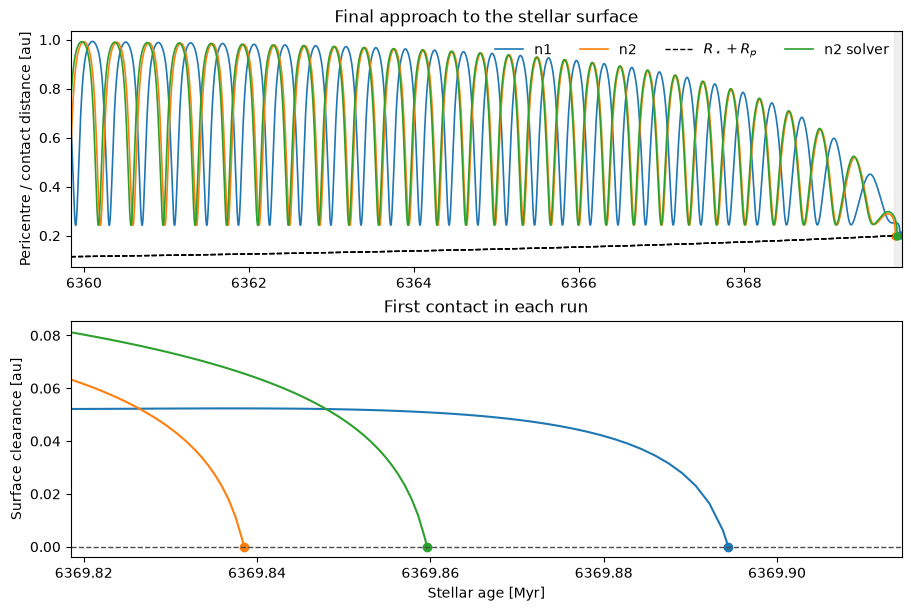

The upper panel shows the last 10 Myr of the triple’s approach. The lower panel resolves the three contact times on the same stellar-age axis. Each marker is the first surface contact for that run.

## How precisely do the runs agree?

Halving the coupling interval passed in isolation. Changing the late-AGB source passed for both systems, as expected because the two sources share the earlier stellar history and contact occurred before the tracks diverged.

For the triple, both the coupling and orbital-solver comparisons missed the one-year contact-time target. At shared ages, both $|\Delta e|$ and $|\Delta q|$ first crossed their limits (0.001 and 0.001 au) at **31.393 Myr** (coupling) and **33.359 Myr** (solver). All three runs had 99 sampled eccentricity peaks over the first 50 Myr. The plot below uses the 33 peaks printed in the original notebook between 25 and 42 Myr to show how their timing and height begin to differ. A zero timing offset means the peaks fell on the same shared output sample (median spacing 13 kyr).

In [ ]:
import csv
from io import StringIO

import matplotlib.pyplot as plt

peak_file = ROOT / "data/examples/06_peak_offsets.csv"
if peak_file.is_file():
    with peak_file.open(newline="") as stream:
        peaks = list(csv.DictReader(stream))
else:
    peaks = list(csv.DictReader(StringIO(PEAK_OFFSETS_CSV)))

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(7, 4.4), layout="constrained")
for label in ("n1", "n2 solver"):
    rows = [row for row in peaks if row["comparison"] == label]
    age = [float(row["n2_peak_age_Myr"]) for row in rows]
    axes[0].plot(age, [float(row["peak_time_offset_yr"])/1000 for row in rows], ".-", label=label)
    axes[1].plot(age, [float(row["peak_e_difference"]) for row in rows], ".-")
for ax in axes:
    ax.axhline(0, linewidth=0.7, color="0.55", zorder=0)
axes[0].set_ylabel("Peak offset from n2 [kyr]")
axes[0].legend(frameon=False)
axes[1].set(xlabel="n2 peak age [Myr]", ylabel="Peak eccentricity difference")
plt.show()


In [ ]:
# If you have the archived results, read the exact event ages and all five comparison flags.
checkpoint = REFERENCE / "notebook_06_checkpoint.json"
if checkpoint.is_file():
    report = json.loads(checkpoint.read_text())
    print("Recorded status:", report["status"])
    for mode, case in report["companion_comparison"].items():
        print(f"{mode}: {case['outcome']} at {case['end_age_Myr']:.6f} Myr")
    for name, comparison in report["comparisons"].items():
        print(f"{name}: {comparison['status']}")


## Optional runs on your PC

**1. First 50 Myr.** Allow a few minutes on a laptop as a planning estimate. Set `RUN_EARLY_COMPARISON = True` to compare the original coarse and fine coupling grids for the 2048 triple. This tests the early disagreement at matching ages. Use the small `data/examples/06_early_triple.npz` exported from the completed cases or restore the 06 run directory first.

**2. Full triple, several hours.** Set `RUN_FULL_TRIPLE = True` to replay one 2048/n2 case from age zero until contact or another stopping condition. It needs the original case’s `run.json`, `driver.npz` and `targets.npy`, supplied in the team data ZIP. For scale, the tighter-solver case in the original suite was still running at 274.6 minutes near contact. The original seven-case suite was already past 33 hours near the end. Each of these replays writes to a separate folder and reuses completed matching work.

**For a PC timing comparison**, set only `RUN_PC_BENCHMARK = True`. It evolves that same 2048/n2 triple from scratch. Allow about **four to five hours** on a machine like mine. The cell compares the endpoint with our original result and prints the path to a small timing and hardware report. Each attempt gets a new folder. With two reports, use `compare_reports([path_to_first_report, path_to_second_report])` in a cell to compare timings.

In [ ]:
if RUN_EARLY_COMPARISON:
    import matplotlib.pyplot as plt

    result = run_early_comparison(ROOT)
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(result["age_Myr"], result["abs_delta_e"] / 0.001, label="Eccentricity")
    ax.plot(result["age_Myr"], result["abs_delta_q_AU"] / 0.001, "--", label="Pericentre")
    ax.axhline(1, color="0.35", lw=1, label="Working limit")
    ax.set(xlabel="Stellar age [Myr]", ylabel="Absolute difference / working limit")
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()

if RUN_PC_BENCHMARK:

    report_path = run_full_triple_benchmark(ROOT)
    print("Share this timing report:", report_path)
elif RUN_FULL_TRIPLE:

    history, summary = run_single_case(ROOT)
    print(f"{summary['outcome']} at {summary['end_age_Myr']:.6f} Myr")
    print(f"Minimum sampled clearance: {summary['minimum_sampled_clearance_AU']:.6g} au")


## What still needs investigating?

- **Why does the triple diverge after 31–33 Myr?** Compare cycle timing, peak eccentricity and time above a fixed eccentricity threshold. Then test whether the accumulated differences carry through to tidal decay and contact on the giant branch.
- **How robust is the brown dwarf’s effect on the outcome?** Repeat matched isolated/triple pairs near the contact boundary at other initial distances and inclinations. Vary the tidal strength and initial spins on selected pairs, and check earlier stellar sampling independently. This one contacting pair cannot locate a survival boundary.

The orbital equations and equilibrium-tide prescription are described by [Hamers (2020)](https://arxiv.org/abs/2004.08327) and [Eggleton, Kiseleva & Hut (1998)](https://arxiv.org/abs/astro-ph/9801246).